# TSA Complaint Data Quality and Service Improvement

**Author:** Violetta Kalinicheva  
**Updated:** October 28, 2026  
**Modified by:** Violetta Kalinicheva

### Decision and audience

How should customer-experience leaders use monthly complaint counts without confusing reporting coverage with service performance? This descriptive visual story audits three nested aggregate grains, identifies reporting gaps, and recommends a defensible complaint-monitoring design. The unit is a monthly complaint-count line item, not a traveler or survey response. The scope is January 2015–January 2024; 2024 is partial.

### Story direction

Start with volume, explain category composition, expose label reliability, compare airport complaint mixes, then assess attribution. No causal effect, airport service ranking, or passenger-adjusted rate is estimated.

## 1. Preserve, audit, and reconcile

The executable workflow reads every frozen raw source, verifies SHA-256 hashes, and fails on an unexpected snapshot. Only aggregate summaries are printed. Set `PROJECT_DATA_DIR` to the external data folder before execution; see the README for acquisition and ethical boundaries.

In [1]:
# I am starting from the raw snapshot so saved outputs cannot conceal missing steps.
import json
from pathlib import Path
from IPython.display import display
import analysis
analysis.setup()
data, facts = analysis.load_and_audit()
display(__import__('pandas').DataFrame(facts['inventory']).drop(columns='sha256'))
print(json.dumps({k:v for k,v in facts.items() if k != 'inventory'}, indent=2))

Matplotlib is building the font cache; this may take a moment.


,file,rows,columns,duplicate_rows,missing_cells
0,complaints-by-airport.csv,41721,4,0,109
1,complaints-by-category.csv,241588,7,0,4042
2,complaints-by-subcategory.csv,504512,11,1405,13464
3,iata-icao.csv,8937,7,0,1175


{
  "complaints": 1021281,
  "airport_months_reconciled": 41721,
  "first_month": "2015-01-01",
  "last_month": "2024-01-01",
  "months": 109,
  "unassigned_complaints": 437786,
  "unassigned_pct": 42.86636097215164,
  "imputed_or_ambiguous_subcategory_complaints": 484349,
  "imputed_or_ambiguous_subcategory_pct": 47.42563506028213,
  "subcategory_duplicate_rows_retained": 1405,
  "complaints_lost_if_deduplicated": 978,
  "unmatched_airport_codes": 5,
  "unmatched_airport_complaints": 289
}


## 2. Establish the timeline

What changed in recorded volume, using only like-for-like complete years?

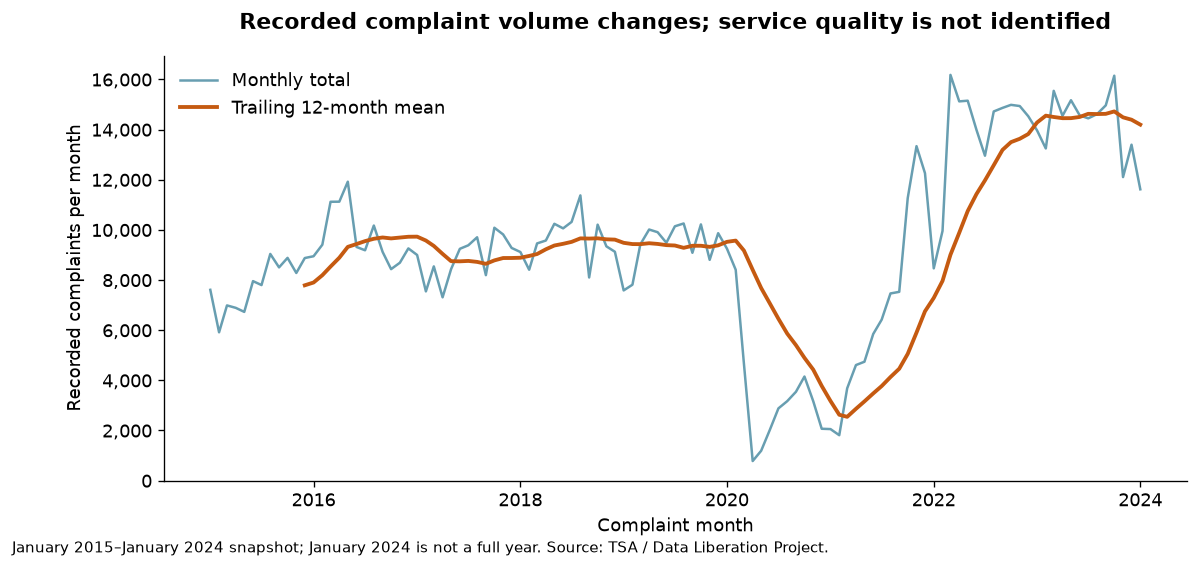

,year,complaints,coverage
0,2015,93481,12 months
1,2016,116714,12 months
2,2017,106552,12 months
3,2018,115342,12 months
4,2019,112610,12 months
5,2020,45326,12 months
6,2021,81033,12 months
7,2022,165876,12 months
8,2023,172729,12 months
9,2024,11618,January only


In [2]:
# I am checking this comparison before interpreting the visual.
result = analysis.timeline(data, facts)
display(result)

### Interpretation

Recorded complaints fell from 112,610 in 2019 to 45,326 in 2020, then reached 172,729 in 2023. January 2024 is displayed as a single month, never compared with a full year. Reporting access, travel activity, and issue mix can all change counts; this line does not identify service quality.

## 3. Separate the category story

Did all types of complaints rise together?

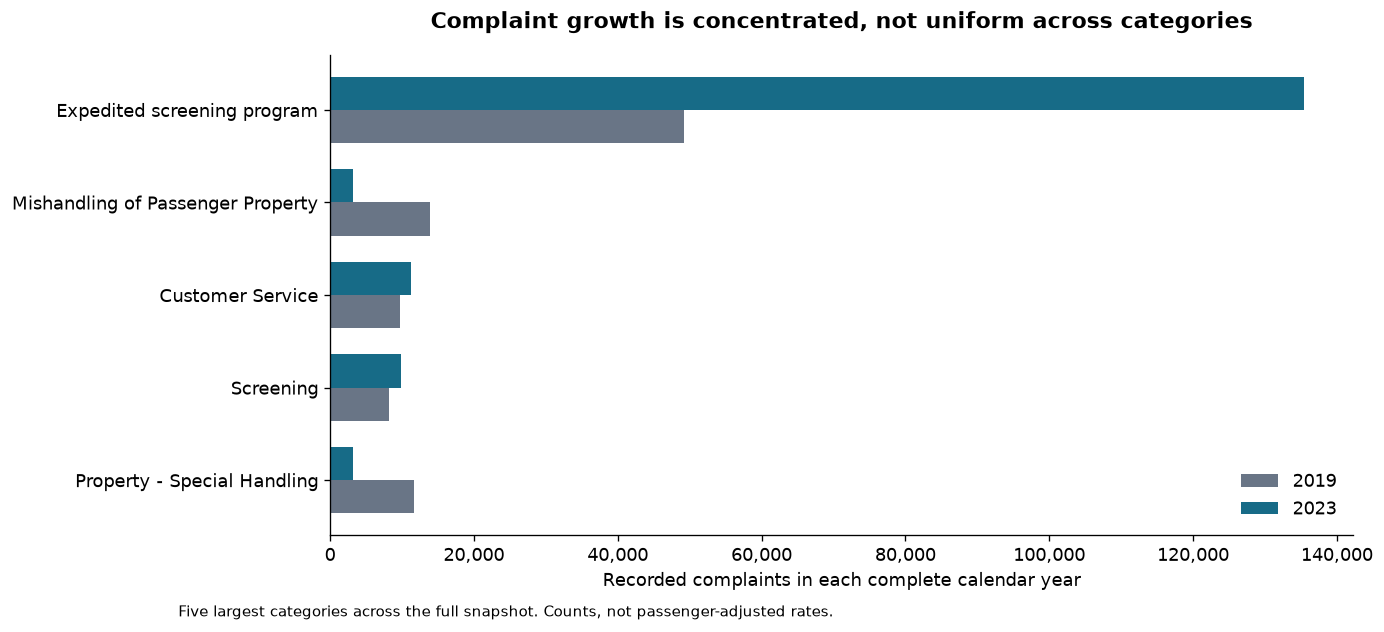

year,2019,2023
clean_cat,,
Property - Special Handling,11658,3149
Screening,8238,9818
Customer Service,9657,11196
Mishandling of Passenger Property,13862,3166
Expedited Passenger Screening Program,49173,135469


In [3]:
# I am checking this comparison before interpreting the visual.
result = analysis.composition(data, facts)
display(result)

### Interpretation

Expedited Passenger Screening Program accounts for 569,943 complaints (55.8% of the snapshot). The 2019–2023 paired bars show concentrated rather than uniform growth. The Data Liberation Project documents reporting-system changes as a comparability caveat; this analysis does not assign a causal fraction of growth to any change.

## 4. Make classification uncertainty visible

How much detail relies on upstream reconstruction?

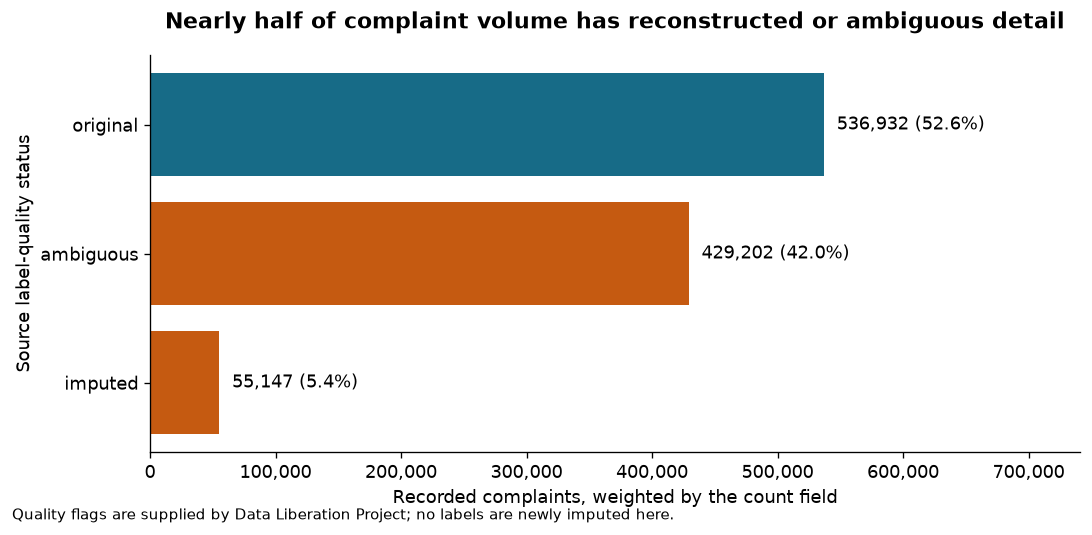

,complaints
clean_subcat_status,
imputed,55147
ambiguous,429202
original,536932


In [4]:
# I am checking this comparison before interpreting the visual.
result = analysis.reliability(data, facts)
display(result)

### Interpretation

Imputed or ambiguous subcategory labels account for 484,349 complaints (47.4%). These are count-weighted shares, not percentages of source rows. No additional category imputation is performed here. The distinction matters because issue-level action should not treat uncertain labels as exact observations.

## 5. Compare mixes, not airport quality

Which complaint categories are unusually prominent among the eight highest-volume airports?

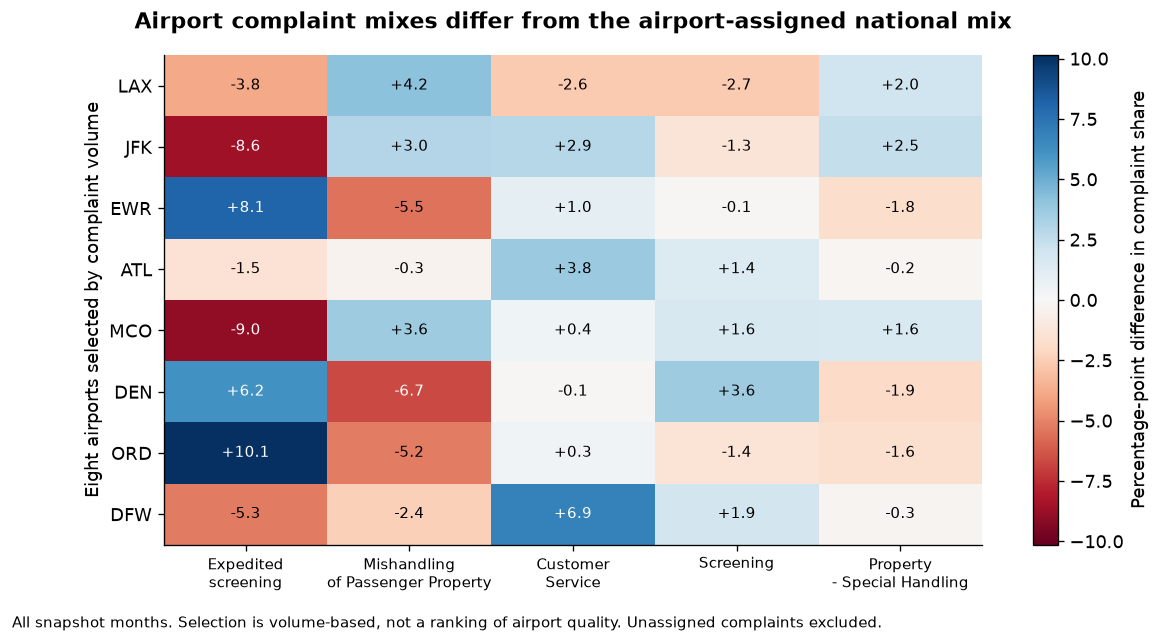

clean_cat,Expedited Passenger Screening Program,Mishandling of Passenger Property,Customer Service,Screening,Property - Special Handling
airport,,,,,
LAX,-3.8,4.2,-2.6,-2.7,2.0
JFK,-8.6,3.0,2.9,-1.3,2.5
EWR,8.1,-5.5,1.0,-0.1,-1.8
ATL,-1.5,-0.3,3.8,1.4,-0.2
MCO,-9.0,3.6,0.4,1.6,1.6
DEN,6.2,-6.7,-0.1,3.6,-1.9
ORD,10.1,-5.2,0.3,-1.4,-1.6
DFW,-5.3,-2.4,6.9,1.9,-0.3


In [5]:
# I am checking this comparison before interpreting the visual.
result = analysis.airport_profiles(data, facts)
display(result)

### Interpretation

The color and labels show percentage-point deviations from the airport-assigned national complaint mix. Differences suggest targeted questions for local reviews, not differences in service failure risk. Selection by raw complaint volume favors large or more reportable airports; no passenger or screening denominators are available.

## 6. End with reporting fitness

Did the fraction of complaints without airport attribution change?

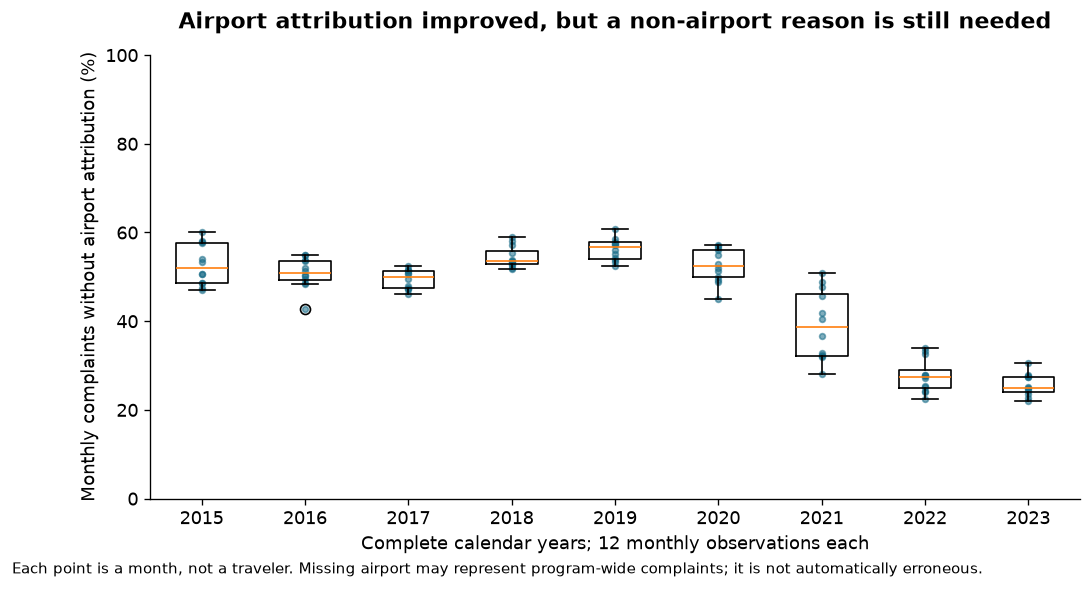

,unassigned_pct
year_month,
2015-01,57.752957
2015-02,60.108181
2015-03,57.570120
2015-04,57.988681
2015-05,53.952452
...,...
2023-09,27.727668
2023-10,23.561830
2023-11,21.964315


In [6]:
# I am checking this comparison before interpreting the visual.
result = analysis.attribution(data, facts)
display(result)

### Interpretation

The median monthly unassigned share fell from approximately 56.7% in 2019 to 24.9% in 2023. Across all months, 437,786 complaints (42.9%) are unassigned. Missing airport is not automatically erroneous: complaints can concern a national program rather than a single location. January 2024 is excluded from complete-year boxplots.

## Conclusion and call to action

Use a validated airport code **or an explicit non-airport reason**, preserve label-quality flags, and monitor local issue composition. Add screening/passenger denominators before comparing airport complaint rates. The strongest demonstrated skill is common-grain reconciliation: all 41,721 airport-month totals agree across three nested datasets. Removing 1,405 repeated-looking subcategory rows would lose 978 complaints and break that reconciliation, so they are retained.

### Design and ethical considerations

Counts and denominators are named, zero baselines are used for bars, full-year and partial-year comparisons are separated, and uncertainty is visible. Figures are aggregate-only. The airport lookup is audited with a many-to-one merge but no geographic claims depend on unverified matches. This notebook is a visual report, not a validated Tableau workbook.

### Sources and attribution

[Data Liberation Project — TSA complaint counts](https://github.com/data-liberation-project/tsa-complaint-counts), frozen revision `e9f8b5e89b4774eb97b93165ee96b4bc986d4319`; [IP2Location IATA/ICAO list](https://github.com/ip2location/ip2location-iata-icao). Source documentation checked October 28, 2026. Both datasets are CC BY-SA 4.0; derived complaint tables/figures in this package are offered under the same license. Original code is MIT. See sources.json for byte-level provenance.

In [7]:
# I am recording actual rerun findings and confirming source preservation.
manifest = json.loads(Path('sources.json').read_text())
import os
source_folder = Path(os.environ['PROJECT_DATA_DIR'])
assert all(analysis.source_hash(source_folder / x['file']) == x['sha256'] for x in manifest['files'])
facts['raw_sources_unchanged'] = True
Path('outputs/metrics.json').write_text(json.dumps(facts, indent=2) + '\n')
print('All assertions passed; raw source hashes unchanged. Aggregate outputs only.')

All assertions passed; raw source hashes unchanged. Aggregate outputs only.
